# Start Here: Forecasting Done Right

> **Who is this for:** complete beginners who want to predict future values (sales, demand, visitors) and, above all, want to know whether their forecast is *really* good.
>
> **What you will learn:**
> - What a time series is: trend, seasonality and noise
> - Why a random train/test split is wrong for time series, and how to split by time
> - Naive baselines (last value, seasonal naive, moving average) and the metrics MAE, RMSE and MAPE
> - Two simple models (Holt-Winters and a lag-feature regression) and how to compare them fairly
> - **Leakage**: how a forecast can secretly peek at the future and look far better than it is
> - Rolling-origin backtesting, and simple prediction intervals
>
> **Prerequisites:** basic Python ([../01_Python/01_basic.ipynb](../01_Python/01_basic.ipynb)), a little pandas and matplotlib ([../02_Data_Analysis/03_pandas.ipynb](../02_Data_Analysis/03_pandas.ipynb), [../02_Data_Analysis/04_matplotlib.ipynb](../02_Data_Analysis/04_matplotlib.ipynb)).
>
> **Time needed:** about 60-90 minutes. All cells run in well under a minute.
>
> **Runs on:** CPU, no API key, no internet (synthetic data generated with a fixed seed, plus one dataset bundled with statsmodels).

## 0. Why this notebook exists

Forecasting has a nasty property: it is very easy to build a forecast that looks excellent on paper and fails on the first real day. The two usual causes are:

1. **No baseline.** A model with "5% error" sounds good, until you learn that "copy last year's number" also gets 5%.
2. **Leakage.** The evaluation accidentally lets the model see information from the future that it will not have in real life.

This notebook teaches the honest workflow from zero, on data where we know the truth because we generate it ourselves.

## 1. Setup

In [1]:
import warnings                                       # to hide one known, harmless warning type
import numpy as np                                    # numbers and arrays
import pandas as pd                                   # tables with dates
import matplotlib.pyplot as plt                       # plots
from statsmodels.tsa.seasonal import seasonal_decompose          # split a series into parts
from statsmodels.tsa.holtwinters import ExponentialSmoothing     # the Holt-Winters model
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression                # a straight-line model
from sklearn.ensemble import RandomForestRegressor               # used once, for the split demo
from sklearn.model_selection import train_test_split            # the WRONG split, for the demo
from sklearn.preprocessing import StandardScaler, MinMaxScaler   # used in the leakage demo

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # optimizer chatter from statsmodels
SEED = 42                                                        # same random numbers every run
pd.set_option("display.precision", 1)                            # show 1 decimal in tables

# One fixed color per "thing", used in every plot of this notebook
COLORS = {"actual": "#2a78d6", "last value": "#eb6834", "seasonal naive": "#1baf7a",
          "moving average": "#eda100", "Holt-Winters": "#e87ba4", "lag regression": "#008300",
          "leaky": "#6250d6"}
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})
print("ready")

ready


**What just happened?** We imported the libraries, fixed a random **seed** (a starting number for the random generator, so everyone gets identical data), and chose one colour per series so the same thing always has the same colour in every plot.

## 2. What is a time series?

A **time series** is a list of measurements taken one after another at regular times: daily visitors, monthly sales, hourly temperature. The order matters: you cannot shuffle the rows without destroying the information.

Most business series are a mix of three ingredients:

| Ingredient | Plain meaning | Example |
|---|---|---|
| **Trend** | the slow, long-term direction | the shop slowly gets more customers every year |
| **Seasonality** | a pattern that repeats with a fixed period | every spring is busy, every autumn is quiet |
| **Noise** | the random wiggle left over | a rainy weekend, a delivery problem |

We **generate** 8 years of monthly sales (2017-2024) from these three ingredients, so we know the truth. Our noise "lingers": a surprisingly good month tends to be followed by another good month, which is how real data often behaves.

In [2]:
rng = np.random.default_rng(SEED)                              # seeded random generator
dates = pd.date_range("2017-01-01", periods=96, freq="MS")     # 96 months, "MS" = month start
t = np.arange(96)                                              # 0, 1, 2, ... (months since start)

trend = 200 + 1.5 * t                                          # starts at 200, +1.5 units per month
seasonality = 30 * np.sin(2 * np.pi * (dates.month - 1) / 12)  # +/-30 units, repeats every 12 months
shocks = rng.normal(0, 8, size=96)                             # fresh random surprise each month
noise = np.zeros(96)
for i in range(96):                                            # each month keeps 70% of last month's noise
    noise[i] = (0.7 * noise[i - 1] if i > 0 else 0) + shocks[i]

sales = pd.Series(trend + seasonality + noise, index=dates, name="sales")  # add the ingredients
print(sales.head(), "\n...")
print("Months:", len(sales), "| from", sales.index[0].date(), "to", sales.index[-1].date())

2017-01-01    202.4
2017-02-01    209.9
2017-03-01    230.4
2017-04-01    243.0
2017-05-01    222.3
Freq: MS, Name: sales, dtype: float64 
...
Months: 96 | from 2017-01-01 to 2024-12-01


**What just happened?** We built a pandas `Series` with a date for every month, from January 2017 to December 2024. Each value is trend + seasonality + noise. Let us look at it, and at the three ingredients separately.

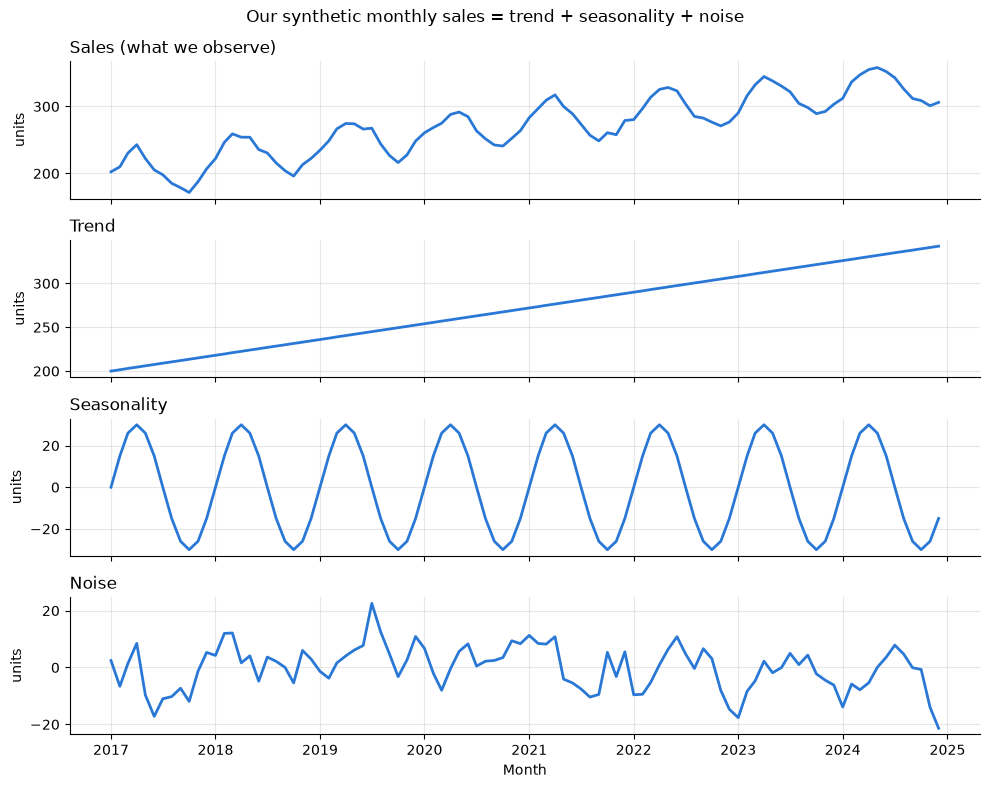

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)        # 4 stacked plots, same time axis
parts = [("Sales (what we observe)", sales), ("Trend", pd.Series(trend, index=dates)),
         ("Seasonality", pd.Series(seasonality, index=dates)), ("Noise", pd.Series(noise, index=dates))]
for ax, (title, series) in zip(axes, parts):
    ax.plot(series.index, series.values, color=COLORS["actual"])
    ax.set_title(title, loc="left"); ax.set_ylabel("units")
axes[-1].set_xlabel("Month")
fig.suptitle("Our synthetic monthly sales = trend + seasonality + noise")
plt.tight_layout(); plt.show()

**What just happened?** The top plot is all we would see in real life. Underneath are the hidden ingredients: a straight upward trend, a wave that peaks every spring (around April) and bottoms out every autumn (around October), and noise that wanders a little above and below zero.

In real life the ingredients are hidden. **Decomposition** estimates them from the data alone. statsmodels' `seasonal_decompose` does it with moving averages:

                            Jan   Feb   Mar   Apr   May   Jun  Jul   Aug  \
true seasonal effect        0.0  15.0  26.0  30.0  26.0  15.0  0.0 -15.0   
estimated by decomposition -3.0  13.0  25.0  31.0  27.0  17.0  2.0 -16.0   

                             Sep   Oct   Nov   Dec  
true seasonal effect       -26.0 -30.0 -26.0 -15.0  
estimated by decomposition -26.0 -32.0 -26.0 -13.0  


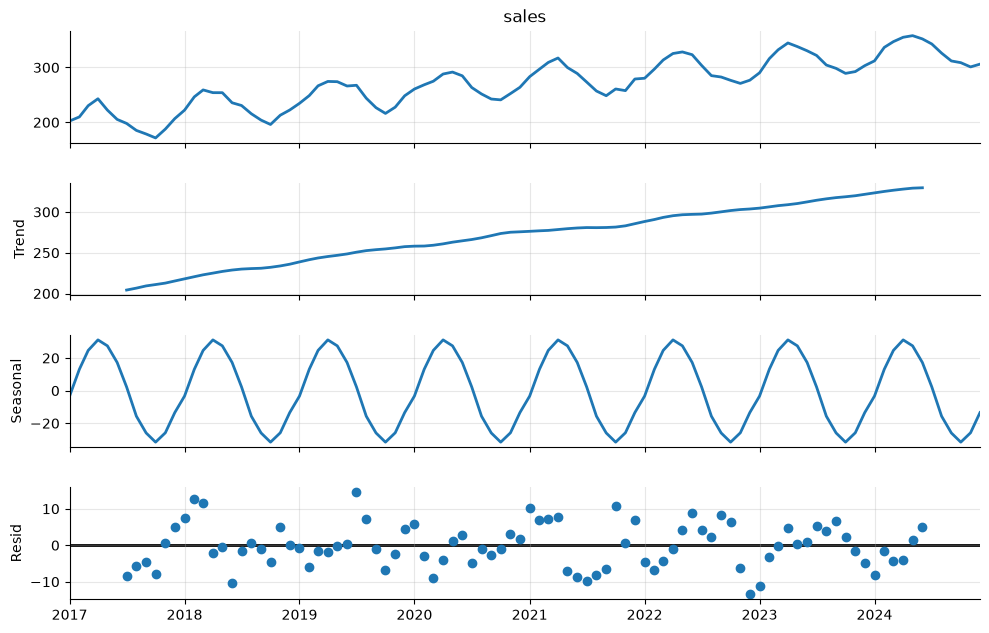

In [4]:
decomposition = seasonal_decompose(sales, model="additive", period=12)   # period=12: yearly pattern in monthly data
estimated = pd.DataFrame({"true seasonal effect": seasonality[:12],
                          "estimated by decomposition": decomposition.seasonal.iloc[:12].values},
                         index=dates[:12].strftime("%b"))                 # Jan, Feb, ...
print(estimated.T.round(0))
decomposition.plot(); plt.gcf().set_size_inches(10, 7); plt.show()

**What just happened?** **Additive** means we assume sales = trend + seasonal + residual (the parts add up). The table compares the true seasonal effect for each month with the estimate: they agree within a few units (for example, roughly +30 in April and roughly -30 in October). The plot shows the estimated trend, seasonal and **residual** (what is left over) parts. The trend line is missing for the first and last 6 months, because a 12-month moving average needs 6 months on each side.

`seasonal_decompose` needs at least two full cycles of data. Here is what happens if you give it less; read the error message:

In [5]:
try:
    seasonal_decompose(sales.iloc[:18], model="additive", period=12)   # only 18 months of data
except ValueError as err:
    print("ValueError:", err)

ValueError: x must have 2 complete cycles requires 24 observations. x only has 18 observation(s)


**What just happened?** The error says the data must have 2 complete cycles, which requires 24 observations, and we gave it 18. Error messages usually tell you exactly what is wrong; read them before searching the internet.

## 3. Why a random train/test split is WRONG for time series

To judge a model we hide some data (the **test set**), train on the rest (the **training set**), and check how well it predicts the hidden part.

In ordinary machine learning we pick the test rows **at random**. For forecasting that is a mistake: a random test month sits *between* training months, so the model only has to fill a gap (**interpolation**), while real forecasting means predicting *after* the last known month (**extrapolation**). Let us measure the difference with the same model, a random forest using only "month number" and "month of year" as inputs.

In [6]:
X = pd.DataFrame({"t": t, "month": dates.month}, index=dates)   # inputs: time index + calendar month

# WRONG: 12 random months as the test set
X_tr, X_te, y_tr, y_te = train_test_split(X, sales, test_size=12, random_state=SEED)
rf = RandomForestRegressor(n_estimators=200, random_state=SEED).fit(X_tr, y_tr)
mae_random = np.mean(np.abs(y_te - rf.predict(X_te)))           # average size of the error

# RIGHT: the last 12 months as the test set
rf = RandomForestRegressor(n_estimators=200, random_state=SEED).fit(X.iloc[:-12], sales.iloc[:-12])
mae_time = np.mean(np.abs(sales.iloc[-12:] - rf.predict(X.iloc[-12:])))

print(f"Random split   -> average error {mae_random:.1f} units")
print(f"Time-based split -> average error {mae_time:.1f} units")

Random split   -> average error 8.1 units
Time-based split -> average error 16.8 units


**What just happened?** The same model looks about **twice as good** with the random split (an average error of about 8 units vs about 17). The random split measured an easy task: the forest could look at the months just before and after each hidden month. With the time-based split it has to predict 2024 from the past only, and a random forest cannot extend a trend beyond the values it has seen, so it falls behind. Only the time-based number tells you what will happen in real use.

> ⚠️ **Common mistake:** using `train_test_split(..., shuffle=True)` (the default) or ordinary `KFold` cross-validation on time series. Use a time-based split, or `sklearn.model_selection.TimeSeriesSplit`.

From now on: **train = 2017-2023 (84 months), test = 2024 (12 months)**. We pretend it is the end of December 2023 and we must forecast all of 2024 at once. The number of steps we forecast ahead (here 12 months) is called the **horizon**.

train: 2017-01-01 -> 2023-12-01 (84 months)
test:  2024-01-01 -> 2024-12-01 (12 months)


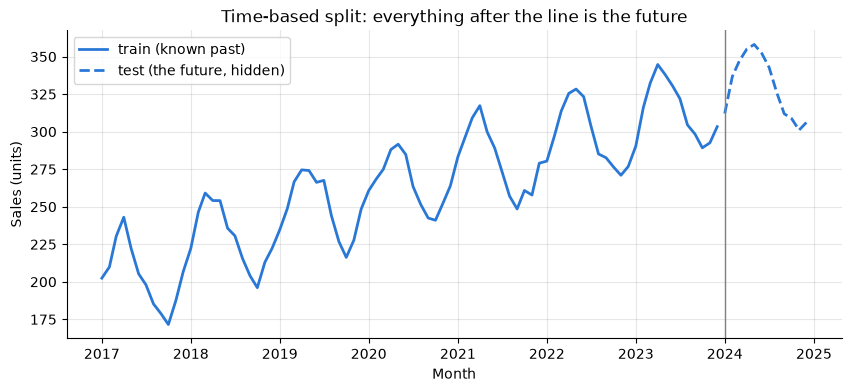

In [7]:
train, test = sales.iloc[:-12], sales.iloc[-12:]             # split by time, never shuffle
HORIZON = len(test)                                          # 12 months ahead
print("train:", train.index[0].date(), "->", train.index[-1].date(), f"({len(train)} months)")
print("test: ", test.index[0].date(), "->", test.index[-1].date(), f"({len(test)} months)")

plt.plot(train.index, train, color=COLORS["actual"], label="train (known past)")
plt.plot(test.index, test, color=COLORS["actual"], linestyle="--", label="test (the future, hidden)")
plt.axvline(test.index[0], color="gray", linewidth=1)        # the forecast origin
plt.title("Time-based split: everything after the line is the future")
plt.xlabel("Month"); plt.ylabel("Sales (units)"); plt.legend(); plt.show()

**What just happened?** The vertical line is the **forecast origin**: the moment we make the forecast. Everything to its left is allowed; everything to its right (dashed) is hidden until we score the forecast.

## 4. Metrics: how wrong is a forecast?

The **error** for one month is `actual - forecast`. To summarise 12 errors we use:

| Metric | How it is computed | Plain meaning |
|---|---|---|
| **MAE** (mean absolute error) | average of the error sizes, ignoring the sign | "on average we are off by this many units" |
| **RMSE** (root mean squared error) | square the errors, average, take the square root | like MAE, but big misses count extra; always at least as large as MAE |
| **MAPE** (mean absolute percentage error) | average of `|error| / actual`, in % | "on average we are off by this % of the actual value" |

MAPE is popular because percentages are easy to explain, but it has a serious problem near zero:

In [8]:
def mae(actual, forecast):  return np.mean(np.abs(np.asarray(actual) - np.asarray(forecast)))
def rmse(actual, forecast): return np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2))
def mape(actual, forecast):
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    with np.errstate(divide="ignore"):                       # dividing by 0 gives inf; we allow it here
        return np.mean(np.abs(actual - forecast) / np.abs(actual)) * 100

examples = pd.DataFrame({"actual": [100, 1, 0], "forecast": [90, 2, 1]},
                        index=["big product", "tiny product", "zero sales"])
examples["abs error"] = (examples.actual - examples.forecast).abs()
examples["APE %"] = [mape([a], [f]) for a, f in zip(examples.actual, examples.forecast)]
examples

,actual,forecast,abs error,APE %
big product,100,90,10,10.0
tiny product,1,2,1,100.0
zero sales,0,1,1,inf


**What just happened?** All three forecasts are wrong by 10 units or less, but: missing 100 by 10 is 10%; missing 1 by 1 is **100%**; and missing 0 by 1 is **infinite** (division by zero). One slow-selling product can dominate an average MAPE. For series that can be near zero, prefer MAE or a scaled error (for example MAE divided by the average actual value). Our sales are always far from zero, so MAPE is safe here.

## 5. Baselines first

A **baseline** is a forecast so simple it needs no model. Every real model must beat it, otherwise the model is not worth its complexity.

| Baseline | Rule | Good when |
|---|---|---|
| **Last value** (naive) | every future month = the last known month | no trend, no seasonality |
| **Seasonal naive** | each future month = the same month last year | strong yearly pattern |
| **Moving average** | every future month = average of the last 3 months | noisy, flat series |

In [9]:
forecasts = {}                                                         # model name -> 12 forecasts
forecasts["last value"] = np.repeat(train.iloc[-1], HORIZON)           # Dec 2023, twelve times
forecasts["seasonal naive"] = train.iloc[-12:].values                  # Jan-Dec 2023, shifted one year
forecasts["moving average"] = np.repeat(train.iloc[-3:].mean(), HORIZON)  # mean of Oct-Dec 2023

def score_table(forecasts, actual):
    rows = {name: {"MAE": mae(actual, f), "RMSE": rmse(actual, f), "MAPE %": mape(actual, f)}
            for name, f in forecasts.items()}
    return pd.DataFrame(rows).T.sort_values("MAE")                     # best (smallest MAE) first

score_table(forecasts, test)

,MAE,RMSE,MAPE %
seasonal naive,16.3,17.4,4.9
last value,26.9,33.4,7.8
moving average,34.8,40.3,10.2


**What just happened?** We made three baseline forecasts for 2024 and scored them on the hidden test year. **Seasonal naive** is clearly the best baseline (MAE about 16 units, roughly 5%), because our data has a strong yearly pattern. "Last value" and "moving average" ignore the seasons: they copy a quiet autumn/winter level into the busy spring, which is why their errors are larger. A plot shows why:

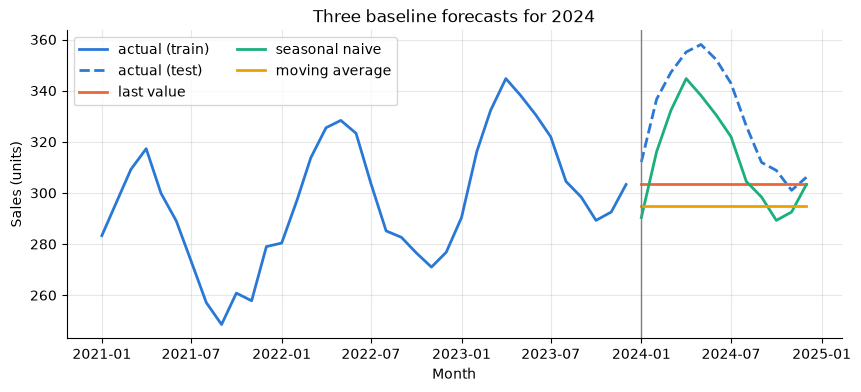

In [10]:
plt.plot(train.index[-36:], train.iloc[-36:], color=COLORS["actual"], label="actual (train)")
plt.plot(test.index, test, color=COLORS["actual"], linestyle="--", label="actual (test)")
for name in ["last value", "seasonal naive", "moving average"]:
    plt.plot(test.index, forecasts[name], color=COLORS[name], label=name)
plt.axvline(test.index[0], color="gray", linewidth=1)
plt.title("Three baseline forecasts for 2024"); plt.xlabel("Month"); plt.ylabel("Sales (units)")
plt.legend(ncol=2); plt.show()

**What just happened?** The flat lines (last value, moving average) cannot follow the seasonal wave. Seasonal naive follows the wave but sits **below** the dashed actuals most of the year: it copies 2023, so it misses one year of trend growth (about 12 months x 1.5 = 18 units). A good model should capture both the wave and the trend.

> 💡 **Tip:** always put the baseline scores in the same table as your model. "MAE 8" means nothing alone; "MAE 8 vs seasonal naive 16" means the model halves the error.

## 6. Two simple models

### 6a. Holt-Winters (exponential smoothing)

**Exponential smoothing** forecasts with weighted averages of the past, where recent months get more weight. The **Holt-Winters** version keeps three running estimates (level, trend and seasonal pattern) and updates them every month. We tell it the trend and season are additive and the season lasts 12 months.

In [11]:
hw_model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit()
forecasts["Holt-Winters"] = hw_model.forecast(HORIZON).values   # 12 months after Dec 2023
print(pd.Series(forecasts["Holt-Winters"], index=test.index.strftime("%b %Y")).round(0).head(6))

Jan 2024    316.0
Feb 2024    331.0
Mar 2024    346.0
Apr 2024    355.0
May 2024    349.0
Jun 2024    339.0
dtype: float64


**What just happened?** `.fit()` learned the smoothing weights from the 84 training months only, and `.forecast(12)` produced one value per month of 2024 (the first six are printed). We score it below, together with the next model.

### 6b. Lag-feature regression (machine learning style)

A **lag** is a past value of the series: "lag 1" is last month, "lag 12" is the same month last year. We turn forecasting into an ordinary table problem: for each month, the inputs are its lags and the target is the month's value. Then any regression model can learn it; we use a plain **linear regression** (a weighted sum of the inputs).

In [12]:
LAGS = [1, 2, 3, 12]                                            # last 3 months + same month last year

def make_lag_table(series):
    table = pd.DataFrame({f"lag_{k}": series.shift(k) for k in LAGS})   # shift(k) = value k months earlier
    table["target"] = series
    return table.dropna()                                       # first 12 rows have no lag_12

lag_table = make_lag_table(train)                               # built from TRAIN only
lag_model = LinearRegression().fit(lag_table[[f"lag_{k}" for k in LAGS]], lag_table["target"])
print(lag_table.head(3).round(1))
print("rows used for training:", len(lag_table))

            lag_1  lag_2  lag_3  lag_12  target
2018-01-01  206.8  187.7  171.6   202.4   222.2
2018-02-01  222.2  206.8  187.7   209.9   246.5
2018-03-01  246.5  222.2  206.8   230.4   259.1
rows used for training: 72


**What just happened?** Each row is one month; the `lag_` columns hold the values 1, 2, 3 and 12 months earlier. We lost the first 12 months because they have no "same month last year", leaving 72 training rows.

Now the important part. To forecast **12 months ahead**, we only know data up to December 2023. Lag 1 for February 2024 is January 2024, which we have not seen yet. The honest solution is a **recursive forecast**: predict January, then use that *prediction* as the lag for February, and so on.

In [13]:
def recursive_forecast(model, history, horizon):
    values = list(history.values)                               # known past (train only)
    for _ in range(horizon):
        features = [[values[-k] for k in LAGS]]                 # lags from known values OR our own forecasts
        next_value = model.predict(pd.DataFrame(features, columns=[f"lag_{k}" for k in LAGS]))[0]
        values.append(next_value)                               # feed the prediction back in
    return np.array(values[-horizon:])                          # only the new 12 months

forecasts["lag regression"] = recursive_forecast(lag_model, train, HORIZON)
score_table(forecasts, test)

,MAE,RMSE,MAPE %
lag regression,6.7,8.3,2.0
Holt-Winters,8.4,9.8,2.6
seasonal naive,16.3,17.4,4.9
last value,26.9,33.4,7.8
moving average,34.8,40.3,10.2


**What just happened?** Both models beat every baseline by a wide margin. On our run the lag regression has an MAE of about 7 units and Holt-Winters about 8, both roughly half of seasonal naive's 16. Both learned the trend *and* the seasons. With only 12 test months, a difference of 1-2 units between the two models could easily be luck; section 8 checks this more carefully.

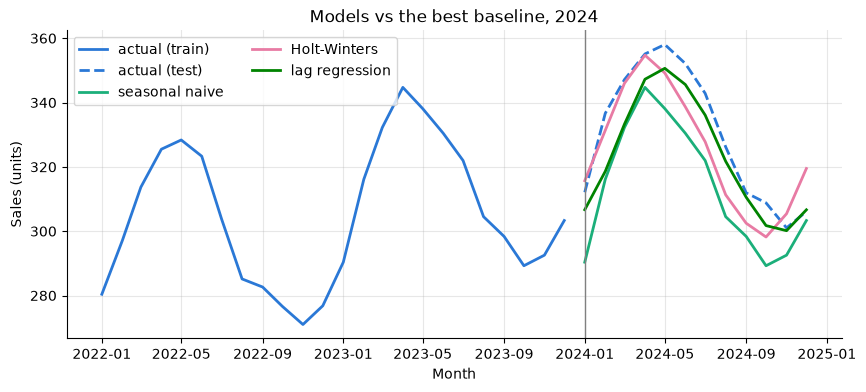

In [14]:
plt.plot(train.index[-24:], train.iloc[-24:], color=COLORS["actual"], label="actual (train)")
plt.plot(test.index, test, color=COLORS["actual"], linestyle="--", label="actual (test)")
for name in ["seasonal naive", "Holt-Winters", "lag regression"]:
    plt.plot(test.index, forecasts[name], color=COLORS[name], label=name)
plt.axvline(test.index[0], color="gray", linewidth=1)
plt.title("Models vs the best baseline, 2024"); plt.xlabel("Month"); plt.ylabel("Sales (units)")
plt.legend(ncol=2); plt.show()

**What just happened?** Both models follow the spring peak and the autumn dip, and sit closer to the dashed actuals than seasonal naive, because they also learned that sales grow every year.

## 7. Leakage: forecasts that secretly see the future

**Leakage** = the evaluation uses information that would not be available at the moment the forecast is made in real life. The score then looks better than reality. Two very common forms:

### 7a. Using true lag values for a multi-step forecast

Instead of the recursive loop, it is tempting to build the lag table for 2024 from the *actual* 2024 values and call `predict` once. For February 2024 that uses the true January 2024 as lag 1: a value we do **not** have at the end of December 2023.

In [15]:
full_table = make_lag_table(sales)                                # lags built from ALL data, incl. 2024
leaky_inputs = full_table.loc[test.index, [f"lag_{k}" for k in LAGS]]
forecasts_leak = {"lag regression (honest, recursive)": forecasts["lag regression"],
                  "lag regression (LEAKY, true lags)": lag_model.predict(leaky_inputs)}
score_table(forecasts_leak, test)

,MAE,RMSE,MAPE %
"lag regression (LEAKY, true lags)",4.1,5.5,1.2
"lag regression (honest, recursive)",6.7,8.3,2.0


**What just happened?** Same model, same test months, but the leaky version looks clearly better: on our run its MAE is about 4 units versus about 7 for the honest recursive forecast, roughly 40% lower, and it would also "beat" Holt-Winters. Nothing about the model improved; the leaky version was simply allowed to see 11 of the 12 months it was predicting, one month at a time. Most of the gain comes from lag 1: real series have short-term momentum (in our data, the lingering noise), and knowing last month's *true* value is a big advantage.

> ⚠️ **Common mistake:** this exact leak is easy to write by accident with `df["lag_1"] = df["sales"].shift(1)` on the full table, then splitting into train/test rows. It is only legitimate if your real use is **one month ahead**, re-forecasting each month after the new actual arrives. Then report it as a one-step-ahead score, not as a 12-month forecast.

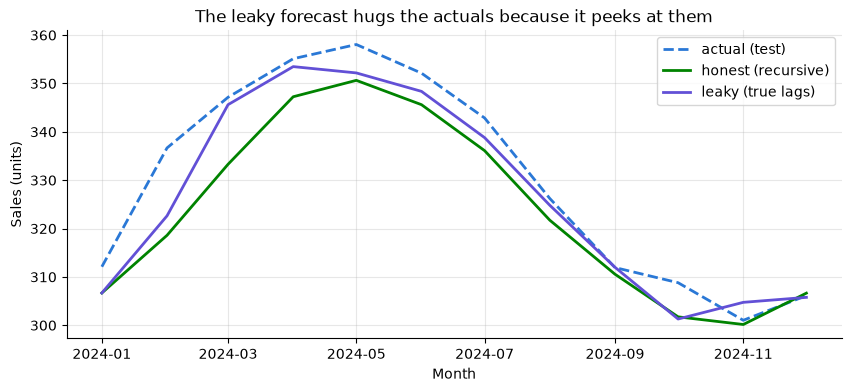

In [16]:
plt.plot(test.index, test, color=COLORS["actual"], linestyle="--", label="actual (test)")
plt.plot(test.index, forecasts["lag regression"], color=COLORS["lag regression"], label="honest (recursive)")
plt.plot(test.index, forecasts_leak["lag regression (LEAKY, true lags)"], color=COLORS["leaky"],
         label="leaky (true lags)")
plt.title("The leaky forecast hugs the actuals because it peeks at them")
plt.xlabel("Month"); plt.ylabel("Sales (units)"); plt.legend(); plt.show()

**What just happened?** The leaky line stays close to the actuals because every month it is corrected with the *true* value of the month before, which is impossible on 31 December 2023. The honest line falls further below the actuals in spring: an early miss is fed back in as a lag and carries forward into later months. That is what you would really have had.

### 7b. Fitting a scaler on the whole series

Many models (neural networks especially) need **scaling**: rescaling numbers to a standard range. `StandardScaler` subtracts the mean and divides by the standard deviation; `MinMaxScaler` maps the minimum to 0 and the maximum to 1. The scaler's statistics must come from the **training data only**. Here is what goes wrong otherwise:

In [17]:
full_minmax = MinMaxScaler().fit(sales.values.reshape(-1, 1))     # WRONG: learned from 2017-2024
train_minmax = MinMaxScaler().fit(train.values.reshape(-1, 1))    # RIGHT: learned from 2017-2023
print("Largest TRAIN value after scaling (full fit): ", full_minmax.transform(train.values.reshape(-1, 1)).max().round(2))
print("Largest TRAIN value after scaling (train fit):", train_minmax.transform(train.values.reshape(-1, 1)).max().round(2))

full_std = StandardScaler().fit(sales.values.reshape(-1, 1))      # mean includes the future
train_std = StandardScaler().fit(train.values.reshape(-1, 1))     # mean of the past only
print(f"\nMean used by the scaler: full fit {full_std.mean_[0]:.0f}, train fit {train_std.mean_[0]:.0f}")
mean_forecasts = {"'average level' using FULL-series mean (leaky)": np.repeat(full_std.mean_[0], HORIZON),
                  "'average level' using TRAIN mean (honest)": np.repeat(train_std.mean_[0], HORIZON)}
score_table(mean_forecasts, test)

Largest TRAIN value after scaling (full fit):  0.93
Largest TRAIN value after scaling (train fit): 1.0

Mean used by the scaler: full fit 271, train fit 263


,MAE,RMSE,MAPE %
'average level' using FULL-series mean (leaky),58.7,62.1,17.5
'average level' using TRAIN mean (honest),67.1,70.1,20.0


**What just happened?** With the full-series fit, the largest training value is scaled to about 0.93 instead of 1.0. That gap quietly tells the model "later values will go higher than anything you trained on", which is information you could not have had in December 2023.

The second part shows the effect on the simplest model that relies on the scaler: "forecast the average level" (a scaled value of 0). The leaky mean (about 271) is pulled up by the higher 2024 values, so the leaky forecast scores better than the honest one (mean about 263). This is a deliberately weak model, used only because the effect is easy to see; in real models the leak can be small or large, and you usually cannot tell which. The rule is simple: **fit every preprocessing step (scalers, imputers, encoders) on the training part only, then apply it to the test part.**

> 💡 **Tip:** a good leakage test is to ask, for every input of every test row, "would I have this exact number at the forecast origin?" If the answer is no for any input, you have a leak.

## 8. Rolling-origin backtesting

One test year is a small sample: 12 months, one forecast origin. Maybe 2024 was simply an easy year. **Backtesting** repeats the whole honest procedure at several past forecast origins, as if we had been forecasting for years.

With an **expanding window** the training data grows each time (`T` = train, `F` = forecast/score, `.` = not used yet):

```
fold 1: TTT F . . .      train 2017-2019, forecast 2020
fold 2: TTTT F . .       train 2017-2020, forecast 2021
fold 3: TTTTT F .        train 2017-2021, forecast 2022
fold 4: TTTTTT F         train 2017-2022, forecast 2023
(2024 stays untouched as our final test year)
```

Each letter is one year. Every fold re-fits every model from scratch on its own training window.

In [18]:
def all_forecasts(history, horizon=12):
    out = {"last value": np.repeat(history.iloc[-1], horizon),
           "seasonal naive": history.iloc[-12:].values,
           "moving average": np.repeat(history.iloc[-3:].mean(), horizon)}
    out["Holt-Winters"] = ExponentialSmoothing(history, trend="add", seasonal="add",
                                               seasonal_periods=12).fit().forecast(horizon).values
    lag_tab = make_lag_table(history)                                     # lags from this fold's train only
    model = LinearRegression().fit(lag_tab[[f"lag_{k}" for k in LAGS]], lag_tab["target"])
    out["lag regression"] = recursive_forecast(model, history, horizon)   # honest recursive forecast
    return out

rows, backtest_errors = [], {}
for train_end in ["2019-12-01", "2020-12-01", "2021-12-01", "2022-12-01"]:   # forecast origins
    history = sales.loc[:train_end]                                       # expanding window
    future = sales.loc[train_end:].iloc[1:13]                             # the next 12 months
    for name, f in all_forecasts(history).items():
        rows.append({"forecast year": future.index[0].year, "model": name, "MAE": mae(future, f)})
        backtest_errors.setdefault(name, []).extend(future.values - f)    # keep errors for section 9
backtest = pd.DataFrame(rows).pivot(index="forecast year", columns="model", values="MAE")
backtest.loc["average"] = backtest.mean()                                 # the number to compare
backtest.round(1)

model,Holt-Winters,lag regression,last value,moving average,seasonal naive
forecast year,,,,,
2020,6.5,6.6,19.1,34.5,16.4
2021,8.1,11.0,22.4,29.3,15.7
2022,8.8,11.5,20.1,31.1,16.8
2023,15.7,8.8,36.7,38.7,16.5
average,9.8,9.5,24.6,33.4,16.4


**What just happened?** The table shows each model's MAE in each backtest year, plus the average. On our run:

- **Holt-Winters and lag regression** have the lowest averages (both around 10 units), far ahead of every baseline.
- They take turns being best: Holt-Winters wins three of the four years, lag regression wins the last one. On the 2024 test year the lag regression was slightly ahead. With this little data, the honest conclusion is "both models are clearly better than the baselines and roughly tied with each other".
- **Seasonal naive** is a steady 16-17 every year. Last value and moving average stay poor.

This is why backtesting matters: one test year could have made either model look like the clear winner.

> 💡 **Tip:** in a real project, run the backtest *before* you look at the final test year, choose your model from the backtest, and only then score the final test year once. Looking at the test year many times and picking the best model turns it into training data.

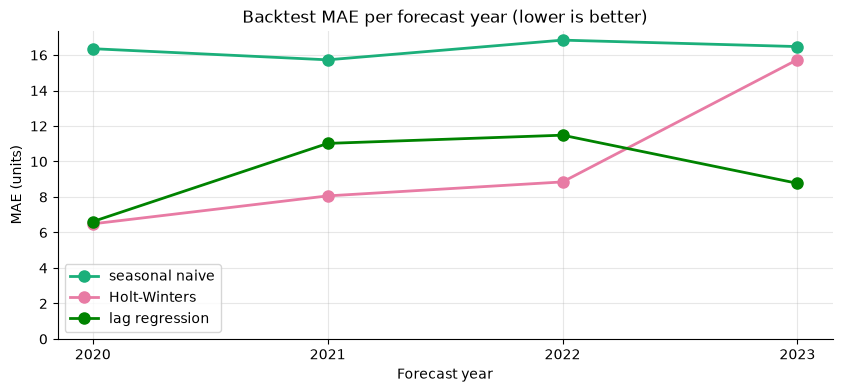

In [19]:
per_year = backtest.drop(index="average")                         # one row per forecast year
years = [int(y) for y in per_year.index]                          # 2020, 2021, 2022, 2023
for name in ["seasonal naive", "Holt-Winters", "lag regression"]:
    plt.plot(years, per_year[name], marker="o", markersize=8, color=COLORS[name], label=name)
plt.title("Backtest MAE per forecast year (lower is better)")
plt.xlabel("Forecast year"); plt.ylabel("MAE (units)"); plt.ylim(bottom=0)
plt.xticks(years); plt.legend(); plt.show()

**What just happened?** The plot shows the same numbers over time: the two models stay below seasonal naive in every year (Holt-Winters only just, in 2023, when its error jumped to about 16), and their lines cross. A model that only wins on average but loses badly in some years would be visible here.

## 9. Uncertainty: prediction intervals

A **point forecast** is one number per month ("we will sell 300"). Reality will almost never hit it exactly. If you stock exactly the point forecast, you will run out of stock in roughly every month where actual sales come in above it:

In [20]:
above = (test.values > forecasts["Holt-Winters"]).mean()          # share of months where actual > forecast
print(f"In 2024, actual sales were ABOVE the Holt-Winters point forecast in {above:.0%} of months")

In 2024, actual sales were ABOVE the Holt-Winters point forecast in 75% of months


**What just happened?** On our run actual sales beat the point forecast in 75% of the 2024 months. Stocking exactly the forecast would have meant running short most of the year. A forecast needs a range.

A **prediction interval** is a range that should contain the actual value with a chosen probability, for example 80%. A simple, honest way to build one: take the errors the model made in the **backtest** (section 8), and use their 10th and 90th **percentiles** (the values that 10% and 90% of the errors fall below). Add them to the point forecast.

In [21]:
errors = np.array(backtest_errors["Holt-Winters"])                # 4 folds x 12 months = 48 past errors
low_q, high_q = np.quantile(errors, [0.10, 0.90])                 # 10th and 90th percentile
point = forecasts["Holt-Winters"]
lower, upper = point + low_q, point + high_q                      # 80% interval around the forecast
inside = ((test.values >= lower) & (test.values <= upper)).mean() # did 2024 fall inside?
print(f"Backtest errors: 10th pct {low_q:.1f}, 90th pct {high_q:.1f}  (from {len(errors)} errors)")
print(f"Share of 2024 months inside the 80% interval: {inside:.0%}")

Backtest errors: 10th pct -12.3, 90th pct 17.8  (from 48 errors)
Share of 2024 months inside the 80% interval: 92%


**What just happened?** From 48 past errors, the 10th percentile is about -12 and the 90th about +18 units: the interval is not symmetric, because in the backtest Holt-Winters tended to forecast a little too low. On our run 11 of the 12 test months (92%) fell inside the 80% interval. With only 12 months that is consistent with 80% (you would expect about 9-10 months, but a few more or fewer is normal); check coverage over many more months before trusting the exact percentage.

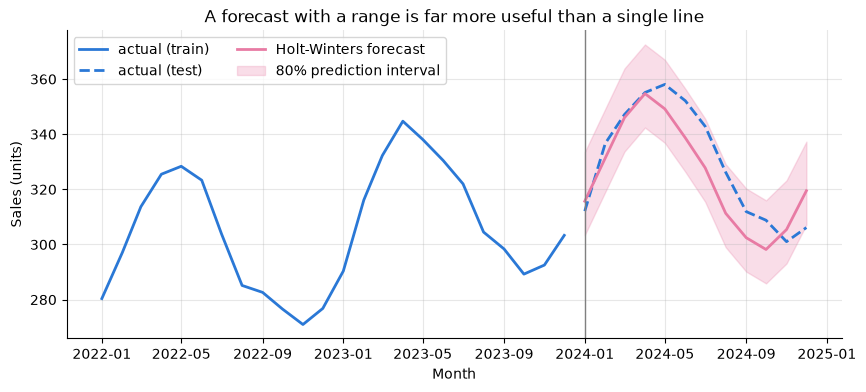

In [22]:
plt.plot(train.index[-24:], train.iloc[-24:], color=COLORS["actual"], label="actual (train)")
plt.plot(test.index, test, color=COLORS["actual"], linestyle="--", label="actual (test)")
plt.plot(test.index, point, color=COLORS["Holt-Winters"], label="Holt-Winters forecast")
plt.fill_between(test.index, lower, upper, color=COLORS["Holt-Winters"], alpha=0.25,
                 label="80% prediction interval")
plt.axvline(test.index[0], color="gray", linewidth=1)
plt.title("A forecast with a range is far more useful than a single line")
plt.xlabel("Month"); plt.ylabel("Sales (units)"); plt.legend(ncol=2); plt.show()

**What just happened?** The shaded band is the 80% interval. A planner can now choose: stock to the upper edge for a product where running out is very expensive, or nearer the middle where leftovers are expensive.

Limits of this simple method: the band has the same width for month 1 and month 12, while real uncertainty usually grows with the horizon; and it assumes future errors look like past errors. With more data you can compute separate percentiles per horizon. More methods: [09_probabilistic_forecasting.ipynb](09_probabilistic_forecasting.ipynb).

## 10. A forecasting checklist

Before you trust (or present) any forecast, check:

1. **Plot the series.** Trend? Seasonality (which period)? Outliers, gaps, level shifts?
2. **Split by time.** Train on the past, test on the future. No shuffling, no ordinary k-fold.
3. **Fix the horizon and the forecast origin** that match real use ("every December, forecast the next 12 months").
4. **Baselines first:** last value, seasonal naive, moving average. Report them next to every model.
5. **Choose metrics deliberately.** MAE/RMSE in units; avoid MAPE when values can be near zero.
6. **Hunt for leakage.** For every input of every test row: would I have this number at the forecast origin? Multi-step forecasts must be recursive (or use direct models trained per horizon), never true future lags.
7. **Fit preprocessing on train only** (scalers, imputers, encoders, feature selection).
8. **Backtest** over several origins (rolling origin, expanding window); look at every fold, not just the average.
9. **Touch the final test set once,** after choosing the model.
10. **Give a range,** not just a point: prediction intervals, checked for coverage.

## Recap

- A **time series** is ordered data; most series are trend + seasonality + noise, and `seasonal_decompose` estimates the parts.
- A **random split** measured interpolation and made a model look about twice as good as it really was; always **split by time**.
- **Baselines** set the bar: seasonal naive was the strong baseline here (MAE about 16 on 2024).
- **Holt-Winters** and a **lag regression** (with an honest **recursive** forecast) roughly halved the baseline error.
- **Leakage** (true future lags, scalers fit on all data) produced better-looking but impossible scores.
- **Rolling-origin backtesting** showed the two models are close to each other and both well ahead of the baselines.
- **Prediction intervals** from backtest error percentiles turn one risky number into a useful range.

## Exercises

**1. (Easy) A 6-month moving average.** Change the moving-average baseline to use the last 6 months instead of 3 and score it on 2024. Better or worse? Why?

<details><summary>Show solution</summary>

```python
ma6 = {"moving average (6)": np.repeat(train.iloc[-6:].mean(), HORIZON),
       "moving average (3)": forecasts["moving average"]}
score_table(ma6, test)
```
You should see the 6-month version do somewhat better (MAE about 28 vs about 35), because Jul-Dec 2023 includes some busier summer months, so its flat line sits higher. But both are still flat lines that cannot follow the seasonal wave, so both stay far behind seasonal naive (about 16). Averaging over more months does not fix a missing seasonality.
</details>

**2. (Easy) Seasonal naive plus trend.** Seasonal naive missed one year of growth. Add the average yearly growth from the training data (`(train.iloc[-12:].mean() - train.iloc[-24:-12].mean())`) to it. How close does it get to the models?

<details><summary>Show solution</summary>

```python
growth = train.iloc[-12:].mean() - train.iloc[-24:-12].mean()       # 2023 average minus 2022 average
drift = {"seasonal naive + growth": train.iloc[-12:].values + growth,
         "seasonal naive": forecasts["seasonal naive"]}
print(f"growth: {growth:.1f} units per year")
score_table(drift, test)
```
The growth comes out at about 16-17 units per year. Adding it removes the systematic under-forecast, and the MAE drops from about 16 to about 5, which on 2024 even beats both of our models (about 7 and 8). A simple baseline with one sensible tweak can be very hard to beat; that is exactly why you always compare against baselines (and backtest them too, before declaring a winner). Note the growth is computed from training data only.
</details>

**3. (Medium) Find the leak.** A colleague writes the code below and reports an amazing MAE. What is wrong?

```python
df = pd.DataFrame({"sales": sales})
df["lag_1"] = df["sales"].shift(1)
df["rolling_mean_3"] = df["sales"].rolling(3).mean()     # mean of this month and the 2 before
df = df.dropna()
train_df, test_df = df.loc[:"2023-12-01"], df.loc["2024-01-01":]
```

<details><summary>Show solution</summary>

Two leaks. (1) `rolling(3).mean()` includes the *current* month, so the input contains the answer itself; it should be `df["sales"].shift(1).rolling(3).mean()`. (2) Even after that fix, `lag_1` and the rolling mean for the 2024 rows are built from true 2024 values, which is only valid for one-step-ahead forecasting. For a 12-month forecast made in December 2023, use a recursive forecast like `recursive_forecast` in section 6.
</details>

**4. (Medium) Per-horizon intervals.** Build the interval separately for each horizon (month 1, month 2, ... month 12 after the origin) from the backtest errors. With 4 folds you only have 4 errors per horizon. What does that tell you about how much data you need?

<details><summary>Show solution</summary>

```python
errs = np.array(backtest_errors["Holt-Winters"]).reshape(4, 12)   # rows = folds, columns = horizon
low_h, high_h = np.quantile(errs, [0.10, 0.90], axis=0)           # one pair per horizon
print(pd.DataFrame({"low": low_h, "high": high_h}, index=range(1, 13)).round(1).T)
```
With only 4 errors per horizon the percentiles jump around from month to month and are basically just the smallest and largest error. Per-horizon intervals need many more backtest folds (for example, monthly origins instead of yearly ones) or a model-based method.
</details>

**5. (Harder) Real data.** statsmodels ships a real dataset, weekly atmospheric CO2 measurements from Mauna Loa (1958-2001), that loads without internet. Turn it into a monthly series and repeat sections 5-6 (seasonal naive vs Holt-Winters, last 24 months as test).

<details><summary>Show solution</summary>

```python
import statsmodels.api as sm
co2 = sm.datasets.co2.load_pandas().data["co2"]           # weekly, has a few missing weeks
co2_monthly = co2.resample("MS").mean().interpolate()     # monthly averages, fill small gaps
tr, te = co2_monthly.iloc[:-24], co2_monthly.iloc[-24:]
f_snaive = np.tile(tr.iloc[-12:].values, 2)               # repeat last year twice for 24 months
f_hw = ExponentialSmoothing(tr, trend="add", seasonal="add", seasonal_periods=12).fit().forecast(24)
score_table({"seasonal naive": f_snaive, "Holt-Winters": f_hw.values}, te)
```
CO2 has a steady upward trend and a yearly cycle, so Holt-Winters should beat seasonal naive clearly (seasonal naive repeats the last year and misses about two years of increase).
</details>

## Where to go next

- [01_time_series_basics.ipynb](01_time_series_basics.ipynb): stationarity, autocorrelation (ACF/PACF), differencing, STL decomposition
- [02_classical_methods.ipynb](02_classical_methods.ipynb): moving averages, exponential smoothing and ARIMA in more depth
- [03_ml_for_forecasting.ipynb](03_ml_for_forecasting.ipynb): lag and window features, `TimeSeriesSplit`, recursive vs direct strategies
- [09_probabilistic_forecasting.ipynb](09_probabilistic_forecasting.ipynb): better prediction intervals and quantile forecasts
- [11_industry_retail_demand_forecasting.ipynb](11_industry_retail_demand_forecasting.ipynb): the full professional workflow (point-in-time features, leakage tests, backtesting, quantiles, ordering decisions)
- [notes/04_Forecasting.md](notes/04_Forecasting.md): the written notes for this module

When you read the other notebooks, apply the checklist from section 10: look for the baseline, the split, and any future information in the features.